In [ ]:
# Install ProDy and the compatible SciPy version used for the analysis

!pip install prody
!pip install scipy==1.9.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.5/37.5 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.1/103.1 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 86.0 MB/s eta 0:00:00
  Attempting uninstall: pyparsing
    Found existing installation: pyparsing 3.2.5
    Uninstalling pyparsing-3.2.5:
      Successfully uninstalled pyparsing-3.2.5


## Define the PPARγ LBD Sequence

The **canonical PPARγ LBD sequence** was added and the required **ProDy** and plotting libraries were imported.

In [ ]:
from prody import *
from pylab import *
pdbids = []
PPARg_Seq = '''DQLNPESADLRALAKHLYDSYIKSFPLTKAKARAILTGKTTDKSPFVIYDMNSLMMGEDKIKFKHITPLQEQSKEVAIRIFQGCQFRSVEAVQEITEYAKSIPGFVNLDLNDQVTLLKYGVHEIIYTMLASLMNKDGVLISEGQGFMTREFLKSLRKPFGDFMEPKFEFAVKFNALELDDSDLAIFIAVIILSGDRPGLLNVKPIEDIQDNLLQALELQLKLNHPESSQLFAKLLQKMTDLRQIVTEHVQLLQVIKKTETDMSLHPLLQEIYKDLY'''

## PDB BLAST Search

Search the **PDB** for structures homologous to the **PPARγ sequence** using BLAST and retrieve hits with **≥90% sequence identity** and **≥70% sequence coverage**.

In [ ]:
blast_record = blastPDB(PPARg_Seq)
pdbids = blast_record.getHits(90,70)

@> Blast searching NCBI PDB database for "DQLNP..."
INFO:.prody:Blast searching NCBI PDB database for "DQLNP..."
@> Blast search completed in 3.5s.
DEBUG:.prody:Blast search completed in 3.5s.


In [ ]:
print(pdbids)
print(len(pdbids))

{'1i7i': {'num': '1', 'bit-score': 562.762, 'score': 1449.0, 'evalue': 0.0, 'query-from': 1, 'query-to': 276, 'hit-from': 17, 'hit-to': 292, 'query-frame': 0, 'hit-frame': 0, 'identity': 276, 'positive': 276, 'gaps': 0, 'align-len': 276, 'qseq': 'DQLNPESADLRALAKHLYDSYIKSFPLTKAKARAILTGKTTDKSPFVIYDMNSLMMGEDKIKFKHITPLQEQSKEVAIRIFQGCQFRSVEAVQEITEYAKSIPGFVNLDLNDQVTLLKYGVHEIIYTMLASLMNKDGVLISEGQGFMTREFLKSLRKPFGDFMEPKFEFAVKFNALELDDSDLAIFIAVIILSGDRPGLLNVKPIEDIQDNLLQALELQLKLNHPESSQLFAKLLQKMTDLRQIVTEHVQLLQVIKKTETDMSLHPLLQEIYKDLY', 'hseq': 'DQLNPESADLRALAKHLYDSYIKSFPLTKAKARAILTGKTTDKSPFVIYDMNSLMMGEDKIKFKHITPLQEQSKEVAIRIFQGCQFRSVEAVQEITEYAKSIPGFVNLDLNDQVTLLKYGVHEIIYTMLASLMNKDGVLISEGQGFMTREFLKSLRKPFGDFMEPKFEFAVKFNALELDDSDLAIFIAVIILSGDRPGLLNVKPIEDIQDNLLQALELQLKLNHPESSQLFAKLLQKMTDLRQIVTEHVQLLQVIKKTETDMSLHPLLQEIYKDLY', 'midline': 'DQLNPESADLRALAKHLYDSYIKSFPLTKAKARAILTGKTTDKSPFVIYDMNSLMMGEDKIKFKHITPLQEQSKEVAIRIFQGCQFRSVEAVQEITEYAKSIPGFVNLDLNDQVTLLKYGVHEIIYTMLASLMNKDGVLISEGQGFMTREFLKSLRKPFGDFMEPKFEFAVKFN

## Download PDB Structures

Download the **PPARγ PDB structures** identified by BLAST and extract **Cα atoms** using **ProDy**, with mmCIF as a fallback.

In [ ]:
from prody import fetchPDB, parsePDB, parseMMCIF
import os

# Create a folder to store PDB files
os.makedirs("PDB", exist_ok=True)

successful_structures = []
failed_pdbids = []

for pdbid in pdbids:
    print(f"⏳ Downloading: {pdbid}")

    pdb_path = None
    structure = None

    try:
        # --- Try PDB first ---
        pdb_path = fetchPDB(pdbid, folder='PDB', compressed=False)

        if pdb_path is not None:
            structure = parsePDB(pdb_path, subset='ca')

        else:
            # --- Fallback to mmCIF ---
            cif_path = fetchPDB(pdbid, folder='PDB', format='cif', compressed=False)

            if cif_path is not None:
                structure = parseMMCIF(cif_path, subset='ca')
            else:
                raise IOError("No PDB or mmCIF available")

        successful_structures.append(structure)
        print(f"✅ Loaded and saved: {pdbid}")

    except Exception as e:
        print(f"⚠️ Failed to load: {pdbid} | Reason: {e}")
        failed_pdbids.append(pdbid)

print("\n❌ PDBs that failed to load:")
print(failed_pdbids)


@> Connecting wwPDB FTP server RCSB PDB (USA).
DEBUG:.prody:Connecting wwPDB FTP server RCSB PDB (USA).
@> Downloading PDB files via FTP failed, trying HTTP.
INFO:.prody:Downloading PDB files via FTP failed, trying HTTP.


⏳ Downloading: 1i7i


@> 1i7i downloaded (PDB/1i7i.pdb)
DEBUG:.prody:1i7i downloaded (PDB/1i7i.pdb)
@> PDB download via HTTP completed (1 downloaded, 0 failed).
DEBUG:.prody:PDB download via HTTP completed (1 downloaded, 0 failed).
@> 516 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:516 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> Connecting wwPDB FTP server RCSB PDB (USA).
DEBUG:.prody:Connecting wwPDB FTP server RCSB PDB (USA).
@> Downloading PDB files via FTP failed, trying HTTP.
INFO:.prody:Downloading PDB files via FTP failed, trying HTTP.


✅ Loaded and saved: 1i7i
⏳ Downloading: 6zly


@> 6zly downloaded (PDB/6zly.pdb)
DEBUG:.prody:6zly downloaded (PDB/6zly.pdb)
@> PDB download via HTTP completed (1 downloaded, 0 failed).
DEBUG:.prody:PDB download via HTTP completed (1 downloaded, 0 failed).
@> 496 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:496 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> Connecting wwPDB FTP server RCSB PDB (USA).
DEBUG:.prody:Connecting wwPDB FTP server RCSB PDB (USA).
@> Downloading PDB files via FTP failed, trying HTTP.
INFO:.prody:Downloading PDB files via FTP failed, trying HTTP.


...

✅ Loaded and saved: 3wj5
⏳ Downloading: 5y2o


@> 5y2o downloaded (PDB/5y2o.pdb)
DEBUG:.prody:5y2o downloaded (PDB/5y2o.pdb)
@> PDB download via HTTP completed (1 downloaded, 0 failed).
DEBUG:.prody:PDB download via HTTP completed (1 downloaded, 0 failed).
@> 519 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:519 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> Connecting wwPDB FTP server RCSB PDB (USA).
DEBUG:.prody:Connecting wwPDB FTP server RCSB PDB (USA).
@> Downloading PDB files via FTP failed, trying HTTP.
INFO:.prody:Downloading PDB files via FTP failed, trying HTTP.


✅ Loaded and saved: 5y2o
⏳ Downloading: 5y2t


@> 5y2t downloaded (PDB/5y2t.pdb)
DEBUG:.prody:5y2t downloaded (PDB/5y2t.pdb)
@> PDB download via HTTP completed (1 downloaded, 0 failed).
DEBUG:.prody:PDB download via HTTP completed (1 downloaded, 0 failed).
@> 524 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:524 atoms and 1 coordinate set(s) were parsed in 0.02s.


✅ Loaded and saved: 5y2t

❌ PDBs that failed to load:
[]


## PDB Download Summary

Plot the number of **successfully downloaded structures** and **failed structures**, including entries that could not be retrieved or parsed in the available PDB/mmCIF format.

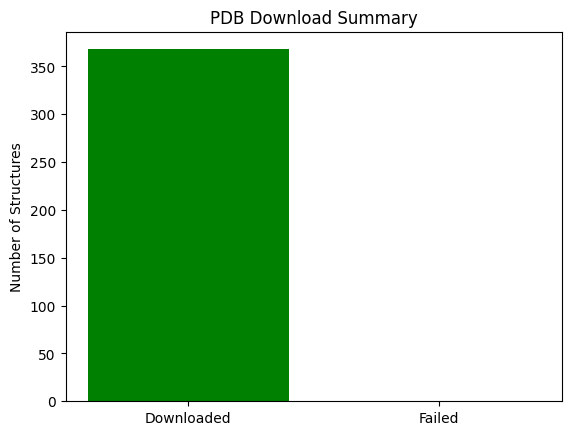

In [ ]:
#Gives a Plot of structures that were downloaded and those that couldnt be, for example some are in cif format in PDN database that ProDy cannot read.
import matplotlib.pyplot as plt

# Data
counts = [len(successful_structures), len(failed_pdbids)]
labels = ['Downloaded', 'Failed']

# Plot
plt.bar(labels, counts, color=['green', 'red'])
plt.title('PDB Download Summary')
plt.ylabel('Number of Structures')
plt.show()

## Convert mmCIF Files to PDB

Convert downloaded **mmCIF/CIF structures** to **PDB format** for subsequent structural analysis.

In [ ]:
#!/usr/bin/env python3

from prody import parseMMCIF, writePDB
import os
import glob
import sys

# --- Define PDB directory ---
PDB_DIR = "PDB"

# --- Check PDB directory exists ---
if not os.path.isdir(PDB_DIR):
    print(f"Error: directory '{PDB_DIR}' not found")
    sys.exit(1)

# --- Change into PDB directory ---
os.chdir(PDB_DIR)
print(f"Working directory: {os.getcwd()}")

# --- Find CIF / MMCIF files ---
cif_files = glob.glob("*.cif") + glob.glob("*.mmcif")

print(f"Found {len(cif_files)} CIF/MMCIF files")

for cif in cif_files:
    pdb = cif.rsplit(".", 1)[0] + ".pdb"

    # Skip if already converted
    if os.path.exists(pdb):
        print(f"⏭️  Skipping (already exists): {pdb}")
        continue

    try:
        ag = parseMMCIF(cif)
        writePDB(pdb, ag)
        print(f"✅ Converted: {cif} → {pdb}")

    except Exception as e:
        print(f"⚠️ Failed to convert {cif}: {e}")


Working directory: /content/PDB
Found 46 CIF/MMCIF files


@> 4210 atoms and 1 coordinate set(s) were parsed in 2.34s.
DEBUG:.prody:4210 atoms and 1 coordinate set(s) were parsed in 2.34s.
@> WARNING Resname A1IP7 too long, cutting resname to 3 characters as A1I


✅ Converted: 9gwl.cif → 9gwl.pdb


@> 4212 atoms and 1 coordinate set(s) were parsed in 1.33s.
DEBUG:.prody:4212 atoms and 1 coordinate set(s) were parsed in 1.33s.
@> WARNING Resname A1IP8 too long, cutting resname to 3 characters as A1I


✅ Converted: 9gwx.cif → 9gwx.pdb


...

✅ Converted: 9gx2.cif → 9gx2.pdb


@> 4222 atoms and 1 coordinate set(s) were parsed in 0.56s.
DEBUG:.prody:4222 atoms and 1 coordinate set(s) were parsed in 0.56s.
@> WARNING Resname A1IPP too long, cutting resname to 3 characters as A1I


✅ Converted: 9gvp.cif → 9gvp.pdb


@> 4114 atoms and 1 coordinate set(s) were parsed in 0.63s.
DEBUG:.prody:4114 atoms and 1 coordinate set(s) were parsed in 0.63s.
@> WARNING Resname A1IQ7 too long, cutting resname to 3 characters as A1I


✅ Converted: 9gz8.cif → 9gz8.pdb


## Load PDB Structures

The script reads all **PDB files** in the `PDB` folder, extracts their **Cα atoms using ProDy**, and stores successfully parsed structures in the `successful_structures` list for subsequent analysis.

In [ ]:
from prody import parsePDB
import os

# Folder containing your PDB files
pdb_folder = 'PDB'
successful_structures = []
failed_pdbids = []

# Loop over PDB files in the folder
for fname in os.listdir(pdb_folder):
    if not fname.endswith('.pdb'):
        continue

    pdb_path = os.path.join(pdb_folder, fname)
    pdbid = fname.split('.')[0]  # Extract PDB ID from filename

    try:
        print(f"📂 Loading: {pdbid}")
        structure = parsePDB(pdb_path, subset='ca')
        successful_structures.append(structure)
        print(f"✅ Loaded: {pdbid}")
    except Exception as e:
        print(f"⚠️ Failed to load: {pdbid} | Reason: {e}")
        failed_pdbids.append(pdbid)

print("\n❌ PDBs that failed to load:")
print(failed_pdbids)


@> 537 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:537 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 267 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:267 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 521 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:521 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 511 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:511 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 515 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:515 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 501 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:501 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 277 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:277 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 516 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:516 atoms and 1 coordinate set(s

📂 Loading: 2zk1
✅ Loaded: 2zk1
📂 Loading: 6fzp
✅ Loaded: 6fzp
📂 Loading: 6c1i
✅ Loaded: 6c1i
📂 Loading: 6o67
✅ Loaded: 6o67
📂 Loading: 6dh9
✅ Loaded: 6dh9
📂 Loading: 8zft
✅ Loaded: 8zft
📂 Loading: 8aty
✅ Loaded: 8aty
📂 Loading: 3sz1
✅ Loaded: 3sz1
📂 Loading: 3k8s
✅ Loaded: 3k8s
📂 Loading: 4oj4
✅ Loaded: 4oj4
📂 Loading: 4r6s
✅ Loaded: 4r6s
📂 Loading: 4e4q
✅ Loaded: 4e4q
📂 Loading: 6k0t


@> 551 atoms and 1 coordinate set(s) were parsed in 0.03s.
DEBUG:.prody:551 atoms and 1 coordinate set(s) were parsed in 0.03s.
@> 519 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:519 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 495 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:495 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 583 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:583 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 507 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:507 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 524 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:524 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 508 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:508 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 272 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:272 atoms and 1 coordinate set(s

✅ Loaded: 6k0t
📂 Loading: 3an4
✅ Loaded: 3an4
📂 Loading: 2vv1
✅ Loaded: 2vv1
📂 Loading: 6ijr
✅ Loaded: 6ijr
📂 Loading: 8zfp
✅ Loaded: 8zfp
📂 Loading: 7ahj
✅ Loaded: 7ahj
📂 Loading: 2q59
✅ Loaded: 2q59
📂 Loading: 4f9m
✅ Loaded: 4f9m
📂 Loading: 8dsy
✅ Loaded: 8dsy
📂 Loading: 2zk0
✅ Loaded: 2zk0
📂 Loading: 8cpi
✅ Loaded: 8cpi
📂 Loading: 6ad9
✅ Loaded: 6ad9
📂 Loading: 4xum
✅ Loaded: 4xum
📂 Loading: 6md4


@> 509 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:509 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 519 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:519 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 503 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:503 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 503 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:503 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 540 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:540 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 498 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:498 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 507 atoms and 1 coordinate set(s) were parsed in 0.03s.
DEBUG:.prody:507 atoms and 1 coordinate set(s) were parsed in 0.03s.
@> 516 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:516 atoms and 1 coordinate set(s

...

✅ Loaded: 3b0r
📂 Loading: 6jey
✅ Loaded: 6jey
📂 Loading: 3osw
✅ Loaded: 3osw
📂 Loading: 9iwk
✅ Loaded: 9iwk
📂 Loading: 2q5s
✅ Loaded: 2q5s
📂 Loading: 3r5n
✅ Loaded: 3r5n
📂 Loading: 6oni
✅ Loaded: 6oni
📂 Loading: 8sc9
✅ Loaded: 8sc9
📂 Loading: 2i4z
✅ Loaded: 2i4z
📂 Loading: 5gtn
✅ Loaded: 5gtn
📂 Loading: 3dzu
✅ Loaded: 3dzu
📂 Loading: 6fzf


@> 572 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:572 atoms and 1 coordinate set(s) were parsed in 0.04s.
@> 519 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:519 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 260 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:260 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 528 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:528 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 540 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:540 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 263 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:263 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 534 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:534 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 278 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:278 atoms and 1 coordinate set(s

✅ Loaded: 6fzf
📂 Loading: 8b8y
✅ Loaded: 8b8y
📂 Loading: 6t6b
✅ Loaded: 6t6b
📂 Loading: 8b8w
✅ Loaded: 8b8w
📂 Loading: 3hod
✅ Loaded: 3hod
📂 Loading: 4xld
✅ Loaded: 4xld
📂 Loading: 8aqm
✅ Loaded: 8aqm
📂 Loading: 6c5q
✅ Loaded: 6c5q
📂 Loading: 5ycp
✅ Loaded: 5ycp
📂 Loading: 5f9b
✅ Loaded: 5f9b
📂 Loading: 6pdz
✅ Loaded: 6pdz
📂 Loading: 2ath


@> 542 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:542 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 271 atoms and 1 coordinate set(s) were parsed in 0.01s.
DEBUG:.prody:271 atoms and 1 coordinate set(s) were parsed in 0.01s.
@> 511 atoms and 1 coordinate set(s) were parsed in 0.03s.
DEBUG:.prody:511 atoms and 1 coordinate set(s) were parsed in 0.03s.
@> 507 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:507 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 505 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:505 atoms and 1 coordinate set(s) were parsed in 0.04s.
@> 499 atoms and 1 coordinate set(s) were parsed in 0.02s.
DEBUG:.prody:499 atoms and 1 coordinate set(s) were parsed in 0.02s.


✅ Loaded: 2ath
📂 Loading: 3b1m
✅ Loaded: 3b1m
📂 Loading: 7lot
✅ Loaded: 7lot
📂 Loading: 8zfs
✅ Loaded: 8zfs
📂 Loading: 3osi
✅ Loaded: 3osi
📂 Loading: 6qj5
✅ Loaded: 6qj5

❌ PDBs that failed to load:
[]


# **CURATION AND EXTRACTION OF PPARγ CHAINS FOR STRUCTURAL ANALYSIS**

**Curate the downloaded structures to isolate PPARγ chains, remove peptides, solvent, hetero atoms, and other molecules, and prepare individual PDB files for subsequent structural analysis.**

## Set the Reference Structure

Set the **modeled 6ONJ structure** as the reference structure for subsequent  analysis.

In [ ]:
# Reorder so '6onj_ca' is first in successful_structures, also remember that this was the modelled structure
for i, struct in enumerate(successful_structures):
    if struct.getTitle() == '6onj_ca':
        # Move it to the front
        reference_structure = successful_structures.pop(i)
        successful_structures.insert(0, reference_structure)
        break

# Confirm
print(f"📌 Reference PDB ID: {successful_structures[0].getTitle()}")


📌 Reference PDB ID: 6onj_ca


## Select Protein Chains

Extract individual **protein chains** from each structure while excluding **solvent and hetero atoms**, with **chain A of 6ONJ** retained as the reference.

In [ ]:
#First filter to add only the protien and chains and remove other things like solvent and hetero atoms

filtered_structures = []

# Step 1: Add only chain A of 6ONJ (reference)
filtered_structures.append(successful_structures[0].select('chain A and protein').copy())

# Step 2: Process remaining structures
for s in successful_structures[1:]:
    # Get unique chain IDs in the structure
    chain_ids = set(atom.getChid() for atom in s)

    for cid in sorted(chain_ids):
        # Select only the protein atoms of that chain
        chain = s.select(f'chain {cid} and protein')
        if chain is not None:
            filtered_structures.append(chain.copy())

print(f"✅ Total protein chains collected (including 6ONJ A): {len(filtered_structures)}")
print(f"🔖 Reference: {filtered_structures[0].getTitle()} | Chain A of 6ONJ")


✅ Total protein chains collected (including 6ONJ A): 783
🔖 Reference: 6onj_ca Selection 'chain A and protein' | Chain A of 6ONJ


## Retain PPARγ Chains and Remove Short Peptides

Retain **PPARγ protein chains (≥100 residues)** and remove short chains such as **coregulator peptides (e.g., NCoR)**, while keeping **6ONJ chain A** as the reference.

In [ ]:
#Filter agin and see the output drops, this second one ensures that chain length is more than 100, so that we can remove peptides like NCoR

filtered_structures = []

# Step 1: Add only chain A of 6ONJ (reference)
ref_chain = successful_structures[0].select('chain A and protein')
if ref_chain is not None and len(ref_chain.getResnums()) >= 100:
    filtered_structures.append(ref_chain.copy())
    print(f"✅ Added reference: {ref_chain.getTitle()} chain A")

# Step 2: Process remaining structures
for s in successful_structures[1:]:
    # Get unique chain IDs
    chain_ids = set(atom.getChid() for atom in s)

    for cid in sorted(chain_ids):
        chain = s.select(f'chain {cid} and protein')
        if chain is None:
            continue

        # Filter by number of standard residues
        if len(chain.getResnums()) >= 100:
            filtered_structures.append(chain.copy())

print(f"✅ Total protein chains collected (≥100 residues): {len(filtered_structures)}")
print(f"🔖 Reference: {filtered_structures[0].getTitle()} | Chain A of 6ONJ")


✅ Added reference: 6onj_ca chain A
✅ Total protein chains collected (≥100 residues): 631
🔖 Reference: 6onj_ca Selection 'chain A and protein' | Chain A of 6ONJ


## Inspect Chain Composition and Metadata

Parse each structure to report the **PDB ID, chain ID, residue count, and molecule identity**, using PDB metadata with **mmCIF as a fallback**.

In [ ]:
from Bio.PDB import PDBParser
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
import pandas as pd
from pathlib import Path

# -------------------------------
# SETUP
# -------------------------------
parser = PDBParser(QUIET=True)
pdb_dir = Path("PDB")
chain_metadata = []

# -------------------------------
# Parse COMPND from PDB
# -------------------------------
def parse_molecule_map_pdb(pdb_file):
    molecule_map = {}
    current_molecule = None

    with open(pdb_file) as f:
        for line in f:
            if not line.startswith("COMPND"):
                continue

            if "MOLECULE:" in line:
                current_molecule = (
                    line.split("MOLECULE:")[1]
                    .split(";")[0]
                    .strip()
                )

            elif "CHAIN:" in line and current_molecule:
                chains = (
                    line.split("CHAIN:")[1]
                    .split(";")[0]
                    .split(",")
                )
                for ch in chains:
                    molecule_map[ch.strip()] = current_molecule.upper()

    return molecule_map


# -------------------------------
# Parse molecule info from mmCIF
# -------------------------------
def parse_molecule_map_cif(cif_file):
    molecule_map = {}

    cif = MMCIF2Dict(str(cif_file))

    desc = cif.get("_entity.pdbx_description", [])
    chains = cif.get("_entity_poly.pdbx_strand_id", [])

    if isinstance(desc, str):
        desc = [desc]
    if isinstance(chains, str):
        chains = [chains]

    for d, ch in zip(desc, chains):
        for chain_id in ch.replace(" ", "").split(","):
            molecule_map[chain_id] = d.upper()

    return molecule_map


# -------------------------------
# Unified resolver (PDB → CIF fallback)
# -------------------------------
def get_molecule_map(pdb_file):
    # 1) Try PDB COMPND
    molecule_map = parse_molecule_map_pdb(pdb_file)
    if molecule_map:
        return molecule_map

    # 2) Fall back to CIF / MMCIF
    pdbid = pdb_file.stem.lower()
    cif_file = pdb_file.parent / f"{pdbid}.cif"
    mmcif_file = pdb_file.parent / f"{pdbid}.mmcif"

    if cif_file.exists():
        return parse_molecule_map_cif(cif_file)

    if mmcif_file.exists():
        return parse_molecule_map_cif(mmcif_file)

    return {}


# -------------------------------
# MAIN LOOP — iterate over PDB files
# -------------------------------
for pdb_file in pdb_dir.glob("*.pdb"):
    pdbid = pdb_file.stem.upper()

    try:
        molecule_map = get_molecule_map(pdb_file)
        structure = parser.get_structure(pdbid, pdb_file)

        for model in structure:
            for chain in model:
                chain_id = chain.id

                residues = [
                    res for res in chain.get_residues()
                    if res.id[0] == " "
                ]

                if not residues:
                    continue

                chain_metadata.append({
                    "PDB ID": pdbid,
                    "Chain ID": chain_id,
                    "Residues": len(residues),
                    "Molecule": molecule_map.get(chain_id, "Unknown")
                })

            break  # only first model

    except Exception as e:
        print(f"⚠️ Failed parsing {pdbid}: {e}")

# -------------------------------
# DATAFRAME
# -------------------------------
df_chains = pd.DataFrame(chain_metadata)

if not df_chains.empty:
    df_chains = df_chains.sort_values(
        by=["Molecule", "PDB ID", "Chain ID"]
    )

from IPython.display import display
display(df_chains)


,PDB ID,Chain ID,Residues,Molecule
207,6AD9,B,10,12-MER PEPTIDE FROM PEROXISOME PROLIFERATOR-AC...
116,1WM0,Y,10,14-MER FROM NUCLEAR RECEPTOR COACTIVATOR 2
665,7WGO,B,12,15-MERIC PEPTIDE FROM NUCLEAR RECEPTOR COACTIV...
79,7WGP,B,11,15-MERIC PEPTIDE FROM NUCLEAR RECEPTOR COACTIV...
489,7WGQ,B,10,15-MERIC PEPTIDE FROM NUCLEAR RECEPTOR COACTIV...
...,...,...,...,...
17,6DGP,C,12,TRAP220 COACTIVATOR PEPTIDE (MEDIATOR OF RNA P...
18,6DGP,D,12,TRAP220 COACTIVATOR PEPTIDE (MEDIATOR OF RNA P...
348,7QB1,A,261,Unknown
349,7QB1,B,260,Unknown


## Standardize PPARγ Chain Metadata

Standardize **PPARγ molecule names**, correct manually verified entries with missing annotations, and save the cleaned chain metadata to a CSV file.

In [ ]:
# -----------------------------------
# STANDARDIZE MOLECULE NAMES IN-MEMORY
# -----------------------------------

STANDARD_NAME = "PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA"

# PDB IDs manually verified as PPARG
pparg_manual_ids = {"7QB1", "9O9N"}

# 1) Fix "Unknown" for verified PPARG structures
df_chains.loc[
    (df_chains["PDB ID"].isin(pparg_manual_ids)) &
    (df_chains["Molecule"] == "Unknown"),
    "Molecule"
] = STANDARD_NAME

# 2) Normalize verbose PDB naming variants
df_chains["Molecule"] = df_chains["Molecule"].replace(
    {
        "PROTEIN (PEROXISOME PROLIFERATOR ACTIVATED RECEPTOR GAMMA)": STANDARD_NAME
    }
)

# -----------------------------------
# SORT + RESET INDEX (CLEAN VIEW)
# -----------------------------------
df_chains = (
    df_chains
    .sort_values(by=["Molecule", "PDB ID", "Chain ID"])
    .reset_index(drop=True)
)

# -----------------------------------
# DISPLAY UPDATED TABLE
# -----------------------------------
from IPython.display import display
display(df_chains)

# -----------------------------------
# WRITE CSV (WITHOUT LOSING MEMORY)
# -----------------------------------
output_csv = "PPARG_chain_metadata.csv"
df_chains.to_csv(output_csv, index=False)

print(f"✅ DataFrame updated in memory and written to {output_csv}")


,PDB ID,Chain ID,Residues,Molecule
0,6AD9,B,10,12-MER PEPTIDE FROM PEROXISOME PROLIFERATOR-AC...
1,1WM0,Y,10,14-MER FROM NUCLEAR RECEPTOR COACTIVATOR 2
2,7WGO,B,12,15-MERIC PEPTIDE FROM NUCLEAR RECEPTOR COACTIV...
3,7WGP,B,11,15-MERIC PEPTIDE FROM NUCLEAR RECEPTOR COACTIV...
4,7WGQ,B,10,15-MERIC PEPTIDE FROM NUCLEAR RECEPTOR COACTIV...
...,...,...,...,...
784,3ET3,P,16,STEROID RECEPTOR COACTIVATOR 1
785,3KMG,B,11,STEROID RECEPTOR COACTIVATOR-1
786,3KMG,E,18,STEROID RECEPTOR COACTIVATOR-1
787,6DGP,C,12,TRAP220 COACTIVATOR PEPTIDE (MEDIATOR OF RNA P...


✅ DataFrame updated in memory and written to PPARG_chain_metadata.csv


## Retain Only PPARγ Chains

The chain metadata revealed that some **non-PPARγ chains, including RXR**, were present in the structure set. The script below matches each **PDB ID and chain ID** against the verified PPARγ metadata and retains only the **PPARγ chains** in `filtered_structures`.

In [ ]:
import pandas as pd

# ---------------------------------------------
# FILTER STRUCTURES USING df_chains (AUTHORITATIVE)
# ---------------------------------------------

STANDARD_NAME = "PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA"

# Build KEEP set from DataFrame
keep_chains = set(
    zip(
        df_chains.loc[df_chains["Molecule"] == STANDARD_NAME, "PDB ID"],
        df_chains.loc[df_chains["Molecule"] == STANDARD_NAME, "Chain ID"],
    )
)

print(f"✅ Chains to KEEP (from df): {len(keep_chains)}")

# ---------------------------------------------
# Apply filter + collect table rows
# ---------------------------------------------
new_filtered_structures = []
kept_rows = []   # for table/CSV

for ag in filtered_structures:
    try:
        pdbid = ag.getTitle()[:4].upper()

        chain_ids = set(ag.getChids())
        if len(chain_ids) != 1:
            print(f"⚠️ Skipping ambiguous chains in {ag.getTitle()}")
            continue

        chain_id = next(iter(chain_ids))

        if (pdbid, chain_id) in keep_chains:
            new_filtered_structures.append(ag)

            kept_rows.append({
                "PDB ID": pdbid,
                "Chain ID": chain_id,
                "Atoms": ag.numAtoms(),
                "Molecule": STANDARD_NAME
            })

        else:
            print(f"⛔ Removing non-PPARG: {pdbid}_{chain_id}")

    except Exception as e:
        print(f"⚠️ Error processing structure {ag}: {e}")

# Replace original list (important)
filtered_structures = new_filtered_structures

print(f"\n✅ Final filtered_structures count: {len(filtered_structures)}")

# ---------------------------------------------
# BUILD + DISPLAY TABLE
# ---------------------------------------------
df_filtered = pd.DataFrame(kept_rows)

df_filtered = (
    df_filtered
    .sort_values(by=["PDB ID", "Chain ID"])
    .reset_index(drop=True)
)

from IPython.display import display
display(df_filtered)

# ---------------------------------------------
# WRITE CSV
# ---------------------------------------------
csv_name = "PPARG_filtered_structures.csv"
df_filtered.to_csv(csv_name, index=False)

print(f"✅ CSV written: {csv_name}")


✅ Chains to KEEP (from df): 607

✅ Final filtered_structures count: 593


,PDB ID,Chain ID,Atoms,Molecule
0,1PRG,A,270,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
1,1PRG,B,270,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
2,2F4B,A,271,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
3,2F4B,B,271,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
4,2FVJ,A,258,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
...,...,...,...,...
588,9V8D,A,261,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
589,9V8E,A,251,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
590,9V8F,A,259,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA
591,9V8G,A,259,PEROXISOME PROLIFERATOR-ACTIVATED RECEPTOR GAMMA


✅ CSV written: PPARG_filtered_structures.csv


## Extract Full-Atom PPARγ Chains

Extract the verified **PPARγ chains** from the original PDB/mmCIF structures and save each as an individual **full-atom PDB file** for downstream structural analysis.

In [ ]:
from prody import parsePDB, parseMMCIF, writePDB
from pathlib import Path

# ---------------------------------------------
# INPUTS
# ---------------------------------------------
pdb_dir = Path("PDB")                  # original structures
outdir  = Path("PPARG_CHAINS_PDB_all")     # output
outdir.mkdir(exist_ok=True)

# Use your authoritative filtered table
df = df_filtered   # or df_chains[df_chains["Molecule"] == STANDARD_NAME]

written = []
failed = []

# ---------------------------------------------
# MAIN LOOP
# ---------------------------------------------
for _, row in df.iterrows():
    pdbid   = row["PDB ID"].lower()
    chainid = row["Chain ID"]

    try:
        # Locate structure file
        pdb_file   = pdb_dir / f"{pdbid}.pdb"
        cif_file   = pdb_dir / f"{pdbid}.cif"
        mmcif_file = pdb_dir / f"{pdbid}.mmcif"

        if pdb_file.exists():
            full = parsePDB(str(pdb_file))
        elif cif_file.exists():
            full = parseMMCIF(str(cif_file))
        elif mmcif_file.exists():
            full = parseMMCIF(str(mmcif_file))
        else:
            raise FileNotFoundError("No PDB/mmCIF file found")

        # Select full-atom protein chain
        sel = full.select(f"chain {chainid} and protein")
        if sel is None:
            raise ValueError("Chain not found")

        outfile = outdir / f"{pdbid.upper()}_{chainid}.pdb"
        writePDB(str(outfile), sel)
        written.append(outfile.name)

    except Exception as e:
        failed.append((pdbid.upper(), chainid, str(e)))

# ---------------------------------------------
# SUMMARY
# ---------------------------------------------
print(f"✅ Full-atom PDBs written : {len(written)}")
print(f"⛔ Failed                : {len(failed)}")

if failed:
    print("\n⛔ Failed entries:")
    for f in failed:
        print(" ", f)


DEBUG:.prody:4897 atoms and 1 coordinate set(s) were parsed in 0.16s.
DEBUG:.prody:4897 atoms and 1 coordinate set(s) were parsed in 0.09s.
DEBUG:.prody:4535 atoms and 1 coordinate set(s) were parsed in 0.11s.
DEBUG:.prody:4535 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:2448 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:4472 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:4472 atoms and 1 coordinate set(s) were parsed in 0.08s.
DEBUG:.prody:4511 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:4511 atoms and 1 coordinate set(s) were parsed in 0.06s.
DEBUG:.prody:2434 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:2528 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:4347 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:4347 atoms and 1 coordinate set(s) were parsed in 0.06s.
DEBUG:.prody:4231 atoms and 1 coordinate set(s) were parsed in 0.08s.
DEBUG:.prody:4231 at

✅ Full-atom PDBs written : 593
⛔ Failed                : 0


## Verify Extracted PPARγ Chains

Compare the original `PDB` directory with the extracted **full-atom PPARγ chain** directory to identify any **missing PDB entries or chains** after filtering and extraction.

In [ ]:
from pathlib import Path
from collections import defaultdict

# -----------------------------
# DIRECTORIES
# -----------------------------
pdb_dir = Path("PDB")
chains_dir = Path("PPARG_CHAINS_PDB_all")

# -----------------------------
# COLLECT PDB IDs FROM PDB/
# -----------------------------
pdb_ids = {
    f.stem.upper()
    for f in pdb_dir.glob("*.pdb")
}

print(f"📁 PDB folder contains {len(pdb_ids)} PDB entries")

# -----------------------------
# COLLECT CHAINS FROM *_all/
# -----------------------------
chains_by_pdb = defaultdict(set)

for f in chains_dir.glob("*.pdb"):
    name = f.stem.upper()  # e.g. 6ONJ_A
    if "_" not in name:
        continue
    pdbid, chain = name.split("_", 1)
    chains_by_pdb[pdbid].add(chain)

print(f"📁 PPARG_CHAINS_PDB_all contains {len(chains_by_pdb)} PDB IDs")

# -----------------------------
# FIND MISSING PDB IDS
# -----------------------------
missing_pdb_ids = sorted(pdb_ids - set(chains_by_pdb.keys()))

print("\n❌ PDB IDs missing entirely from PPARG_CHAINS_PDB_all:")
if missing_pdb_ids:
    for pdbid in missing_pdb_ids:
        print(" ", pdbid)
else:
    print(" None")

# -----------------------------
# FIND MISSING CHAINS PER PDB
# -----------------------------
print("\n⚠️ Chain-level comparison:")

for pdbid in sorted(pdb_ids & set(chains_by_pdb.keys())):
    original_pdb = pdb_dir / f"{pdbid}.pdb"
    if not original_pdb.exists():
        continue

    # Try to infer expected chains from original PDB
    expected_chains = set()

    with open(original_pdb) as f:
        for line in f:
            if line.startswith("ATOM"):
                expected_chains.add(line[21])
    expected_chains.discard(" ")

    existing_chains = chains_by_pdb[pdbid]
    missing_chains = expected_chains - existing_chains

    if missing_chains:
        print(f" {pdbid}: missing chains {sorted(missing_chains)}")

print("\n✅ Comparison complete")


📁 PDB folder contains 368 PDB entries
📁 PPARG_CHAINS_PDB_all contains 348 PDB IDs

❌ PDB IDs missing entirely from PPARG_CHAINS_PDB_all:
  1FM6
  1FM9
  1I7I
  1K74
  1KNU
  1NYX
  1RDT
  1WM0
  1ZEO
  1ZGY
  2ATH
  2PRG
  3PRG
  7E0A
  7WGO
  7WGP
  7WGQ
  8HUM
  8HUP
  9IWK

⚠️ Chain-level comparison:

✅ Comparison complete


## Inspect Missing PDB Entries

Inspect the **PDB entries missing after PPARγ chain extraction** to confirm that they can be parsed and determine their **chain, residue, and protein content**.

In [ ]:
from prody import parsePDB
from pathlib import Path
import pandas as pd

missing_ids = [
    "1FM6","1FM9","1I7I","1K74","1KNU","1NYX","1RDT",
    "1WM0","1ZEO","1ZGY","2ATH","2PRG","3PRG",
    "7E0A","7WGO","7WGP","7WGQ","8HUM","8HUP","9IWK"
]

pdb_dir = Path("PDB")
rows = []

for pdbid in missing_ids:
    try:
        pdb_file = pdb_dir / f"{pdbid.lower()}.pdb"
        if not pdb_file.exists():
            rows.append({
                "PDB ID": pdbid,
                "Parsed": False,
                "Reason": "File not found"
            })
            continue

        ag = parsePDB(str(pdb_file))

        chids = set(ag.getChids())
        resnames = set(ag.getResnames())
        n_atoms = ag.numAtoms()
        n_res   = len(set(zip(ag.getChids(), ag.getResnums())))

        # crude protein test
        protein_like = any(r in {
            "ALA","LEU","GLY","SER","VAL","ASP","GLU","LYS","ARG",
            "ILE","THR","PHE","TYR","TRP","HIS","CYS","ASN","GLN","MET","PRO"
        } for r in resnames)

        rows.append({
            "PDB ID": pdbid,
            "Parsed": True,
            "Atoms": n_atoms,
            "Residues": n_res,
            "Chains seen": ",".join(sorted(chids)),
            "Protein-like": protein_like
        })

    except Exception as e:
        rows.append({
            "PDB ID": pdbid,
            "Parsed": False,
            "Reason": str(e)
        })

df_info = pd.DataFrame(rows)
df_info


DEBUG:.prody:8838 atoms and 1 coordinate set(s) were parsed in 0.27s.
DEBUG:.prody:4342 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:4250 atoms and 1 coordinate set(s) were parsed in 0.12s.
DEBUG:.prody:4405 atoms and 1 coordinate set(s) were parsed in 0.21s.
DEBUG:.prody:4259 atoms and 1 coordinate set(s) were parsed in 0.20s.
DEBUG:.prody:4262 atoms and 1 coordinate set(s) were parsed in 0.19s.
DEBUG:.prody:4027 atoms and 1 coordinate set(s) were parsed in 0.20s.
DEBUG:.prody:2297 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:4214 atoms and 1 coordinate set(s) were parsed in 0.18s.
DEBUG:.prody:2464 atoms and 1 coordinate set(s) were parsed in 0.05s.
DEBUG:.prody:4547 atoms and 1 coordinate set(s) were parsed in 0.08s.
DEBUG:.prody:5004 atoms and 1 coordinate set(s) were parsed in 0.08s.
DEBUG:.prody:2139 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:2272 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:2376 at

,PDB ID,Parsed,Atoms,Residues,Chains seen,Protein-like
0,1FM6,True,8838,1518,"A,B,D,E,U,V,X,Y",True
1,1FM9,True,4342,663,"A,B,D,E",True
2,1I7I,True,4250,580,"A,B",True
3,1K74,True,4405,740,"A,B,D,E",True
4,1KNU,True,4259,556,"A,B",True
5,1NYX,True,4262,604,"A,B",True
6,1RDT,True,4027,687,"A,B,D,E",True
7,1WM0,True,2297,283,"X,Y",True
8,1ZEO,True,4214,625,"A,B",True
9,1ZGY,True,2464,443,"A,B",True


## Identify PPARγ Chains in Missing Structures

Analyze the **PDB entries missing after filtering** and compare their protein-chain sequences against the canonical **PPARγ LBD sequence** to identify PPARγ-like chains.

In [ ]:
from prody import parsePDB
from Bio import pairwise2
from pathlib import Path
import pandas as pd

# ---------------------------------------------
# INPUT: ONLY THESE PDB IDs WILL BE ANALYZED
# ---------------------------------------------
SELECTED_PDBS = [
    "1FM6","1FM9","1I7I","1K74","1KNU","1NYX","1RDT",
    "1WM0","1ZEO","1ZGY","2ATH","2PRG","3PRG",
    "7E0A","7WGO","7WGP","7WGQ","8HUM","8HUP","9IWK"
]

# Canonical PPARG sequence
PPARG_SEQ = (
    "QLNPESADLRALAKHLYDSYIKSFPLTKAKARAILTGKTTDKSPFVIYDMNSLMMGEDK"
    "IKFKHITPLQEQSKEVAIRIFQGCQFRSVEAVQEITEYAKSIPGFVNLDLNDQVTLLKY"
    "GVHEIIYTMLASLMNKDGVLISEGQGFMTREFLKSLRKPFGDFMEPKFEFAVKFNALE"
    "LDDSDLAIFIAVIILSGDRPGLLNVKPIEDIQDNLLQALELQLKLNHPESSQLFAKLL"
    "QKMTDLRQIVTEHVQLLQVIKKTETDMSLHPLLQEIYKDLY"
)

pdb_dir = Path("PDB")
rows = []

# ---------------------------------------------
# MAIN LOOP — ONLY SELECTED FILES
# ---------------------------------------------
for pdbid in SELECTED_PDBS:
    pdb_file = pdb_dir / f"{pdbid.lower()}.pdb"

    if not pdb_file.exists():
        rows.append({
            "PDB ID": pdbid,
            "Chain": None,
            "Length": None,
            "SeqID (%)": None,
            "PPARG-like": False,
            "Error": "File not found"
        })
        continue

    try:
        ag = parsePDB(str(pdb_file))
    except Exception as e:
        rows.append({
            "PDB ID": pdbid,
            "Chain": None,
            "Length": None,
            "SeqID (%)": None,
            "PPARG-like": False,
            "Error": str(e)
        })
        continue

    for chain_id in sorted(set(ag.getChids())):
        sel = ag.select(f"chain {chain_id} and protein and name CA")
        if sel is None:
            continue

        seq = sel.getSequence()
        if not seq or len(seq) < 150:
            continue

        aln = pairwise2.align.globalxx(seq, PPARG_SEQ, one_alignment_only=True)
        if not aln:
            continue

        aln_seq, aln_ref, score, start, end = aln[0]
        seqid = 100.0 * score / max(len(seq), len(PPARG_SEQ))

        rows.append({
            "PDB ID": pdbid,
            "Chain": chain_id,
            "Length": len(seq),
            "SeqID (%)": round(seqid, 1),
            "PPARG-like": seqid >= 85.0
        })

# ---------------------------------------------
# OUTPUT TABLE
# ---------------------------------------------
df_selected_pparg = pd.DataFrame(rows)
df_selected_pparg


DEBUG:.prody:8838 atoms and 1 coordinate set(s) were parsed in 0.27s.
DEBUG:.prody:4342 atoms and 1 coordinate set(s) were parsed in 0.06s.
DEBUG:.prody:4250 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:4405 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:4259 atoms and 1 coordinate set(s) were parsed in 0.06s.
DEBUG:.prody:4262 atoms and 1 coordinate set(s) were parsed in 0.09s.
DEBUG:.prody:4027 atoms and 1 coordinate set(s) were parsed in 0.08s.
DEBUG:.prody:2297 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:4214 atoms and 1 coordinate set(s) were parsed in 0.11s.
DEBUG:.prody:2464 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:4547 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:5004 atoms and 1 coordinate set(s) were parsed in 0.13s.
DEBUG:.prody:2139 atoms and 1 coordinate set(s) were parsed in 0.06s.
DEBUG:.prody:2272 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:2376 at

,PDB ID,Chain,Length,SeqID (%),PPARG-like
0,1FM6,A,232,35.6,False
1,1FM6,D,272,98.9,True
2,1FM6,U,232,35.6,False
3,1FM6,X,272,98.9,True
4,1FM9,A,232,35.6,False
5,1FM9,D,272,98.9,True
6,1I7I,A,258,93.8,True
7,1I7I,B,258,93.8,True
8,1K74,A,232,35.6,False
9,1K74,D,272,98.9,True


## Sanity Check: Validate PPARγ Chain Extraction

Compare the extracted chains against the **sequence-based PPARγ classification** to check for **missing PPARγ chains or incorrectly retained non-PPARγ chains**.

In [ ]:
from pathlib import Path
import pandas as pd

# ---------------------------------------------
# INPUTS
# ---------------------------------------------
chains_dir = Path("PPARG_CHAINS_PDB_all")

# df_pparg_chains : sequence-based truth
df_seq = df_pparg_chains.copy()

# ---------------------------------------------
# BUILD SET FROM *_all FOLDER
# ---------------------------------------------
written_set = set()

for f in chains_dir.glob("*.pdb"):
    stem = f.stem.upper()   # e.g. 6ONJ_A
    if "_" not in stem:
        continue
    pdbid, chain = stem.split("_", 1)
    written_set.add((pdbid, chain))

print(f"📁 Chains present in *_all folder: {len(written_set)}")

# ---------------------------------------------
# BUILD SETS FROM SEQUENCE TABLE
# ---------------------------------------------
true_pparg = set(
    zip(
        df_seq.loc[df_seq["PPARG-like"], "PDB ID"],
        df_seq.loc[df_seq["PPARG-like"], "Chain"]
    )
)

false_pparg = set(
    zip(
        df_seq.loc[~df_seq["PPARG-like"], "PDB ID"],
        df_seq.loc[~df_seq["PPARG-like"], "Chain"]
    )
)

# ---------------------------------------------
# CONSISTENCY CHECKS
# ---------------------------------------------
false_negatives = sorted(true_pparg - written_set)
false_positives = sorted(written_set & false_pparg)
true_positives  = sorted(true_pparg & written_set)

# ---------------------------------------------
# REPORT
# ---------------------------------------------
print("\n✅ TRUE POSITIVES (correctly extracted):", len(true_positives))

print("\n❌ FALSE NEGATIVES (PPARG-like but missing):", len(false_negatives))
for x in false_negatives[:10]:
    print(" ", x)
if len(false_negatives) > 10:
    print(" ...")

print("\n⚠️ FALSE POSITIVES (non-PPARG extracted):", len(false_positives))
for x in false_positives[:10]:
    print(" ", x)
if len(false_positives) > 10:
    print(" ...")

# ---------------------------------------------
# OPTIONAL: TABLES FOR INSPECTION
# ---------------------------------------------
df_false_neg = pd.DataFrame(false_negatives, columns=["PDB ID", "Chain"])
df_false_pos = pd.DataFrame(false_positives, columns=["PDB ID", "Chain"])
df_true_pos  = pd.DataFrame(true_positives,  columns=["PDB ID", "Chain"])

print("\n📊 DataFrames available:")
print(" - df_true_pos")
print(" - df_false_neg")
print(" - df_false_pos")


📁 Chains present in *_all folder: 593

✅ TRUE POSITIVES (correctly extracted): 585

❌ FALSE NEGATIVES (PPARG-like but missing): 27
  ('1FM6', np.str_('D'))
  ('1FM6', np.str_('X'))
  ('1FM9', np.str_('D'))
  ('1I7I', np.str_('A'))
  ('1I7I', np.str_('B'))
  ('1K74', np.str_('D'))
  ('1KNU', np.str_('A'))
  ('1KNU', np.str_('B'))
  ('1NYX', np.str_('A'))
  ('1NYX', np.str_('B'))
 ...

⚠️ FALSE POSITIVES (non-PPARG extracted): 8
  ('2P4Y', np.str_('B'))
  ('3DZU', np.str_('D'))
  ('3DZY', np.str_('D'))
  ('3E00', np.str_('D'))
  ('8ADF', np.str_('B'))
  ('8B90', np.str_('B'))
  ('8C0C', np.str_('B'))
  ('8REJ', np.str_('B'))

📊 DataFrames available:
 - df_true_pos
 - df_false_neg
 - df_false_pos


## Recover Missing PPARγ Chains

Extract the **PPARγ chains identified as false negatives** from the original PDB/mmCIF files and save them as full-atom PDB structures.

In [ ]:
from prody import parsePDB, parseMMCIF, writePDB
from pathlib import Path

# ---------------------------------------------
# INPUTS
# ---------------------------------------------
pdb_dir = Path("PDB")
outdir  = Path("PPARG_CHAINS_PDB_missing")
outdir.mkdir(exist_ok=True)

# df_false_neg must exist
missing_df = df_false_neg.copy()

written = []
failed  = []

# ---------------------------------------------
# MAIN LOOP — ONLY FALSE NEGATIVES
# ---------------------------------------------
for _, row in missing_df.iterrows():
    pdbid   = row["PDB ID"].lower()
    chainid = row["Chain"]

    try:
        pdb_file   = pdb_dir / f"{pdbid}.pdb"
        cif_file   = pdb_dir / f"{pdbid}.cif"
        mmcif_file = pdb_dir / f"{pdbid}.mmcif"

        if pdb_file.exists():
            full = parsePDB(str(pdb_file))
        elif cif_file.exists():
            full = parseMMCIF(str(cif_file))
        elif mmcif_file.exists():
            full = parseMMCIF(str(mmcif_file))
        else:
            raise FileNotFoundError("No structure file found")

        sel = full.select(f"chain {chainid} and protein")
        if sel is None:
            raise ValueError("Chain not found or not protein")

        outfile = outdir / f"{pdbid.upper()}_{chainid}.pdb"
        writePDB(str(outfile), sel)
        written.append(outfile.name)

    except Exception as e:
        failed.append((pdbid.upper(), chainid, str(e)))

# ---------------------------------------------
# SUMMARY
# ---------------------------------------------
print(f"✅ Missing PPARG chains written : {len(written)}")
print(f"⛔ Failed                       : {len(failed)}")

if failed:
    print("\n⛔ Failed entries:")
    for f in failed:
        print(" ", f)


DEBUG:.prody:8838 atoms and 1 coordinate set(s) were parsed in 0.31s.
DEBUG:.prody:8838 atoms and 1 coordinate set(s) were parsed in 0.31s.
DEBUG:.prody:4342 atoms and 1 coordinate set(s) were parsed in 0.22s.
DEBUG:.prody:4250 atoms and 1 coordinate set(s) were parsed in 0.30s.
DEBUG:.prody:4250 atoms and 1 coordinate set(s) were parsed in 0.25s.
DEBUG:.prody:4405 atoms and 1 coordinate set(s) were parsed in 0.24s.
DEBUG:.prody:4259 atoms and 1 coordinate set(s) were parsed in 0.10s.
DEBUG:.prody:4259 atoms and 1 coordinate set(s) were parsed in 0.13s.
DEBUG:.prody:4262 atoms and 1 coordinate set(s) were parsed in 0.08s.
DEBUG:.prody:4262 atoms and 1 coordinate set(s) were parsed in 0.15s.
DEBUG:.prody:4027 atoms and 1 coordinate set(s) were parsed in 0.14s.
DEBUG:.prody:2297 atoms and 1 coordinate set(s) were parsed in 0.08s.
DEBUG:.prody:4214 atoms and 1 coordinate set(s) were parsed in 0.19s.
DEBUG:.prody:4214 atoms and 1 coordinate set(s) were parsed in 0.14s.
DEBUG:.prody:2464 at

✅ Missing PPARG chains written : 27
⛔ Failed                       : 0


## Final PPARγ Structure Dataset

The initial filtering identified **593 PPARγ chains**. Sequence-based sanity checks identified **27 additional PPARγ chains** that were missed during metadata-based filtering, resulting in a final dataset of **620 PPARγ chains**. 

Zip this PPARG_CHAINS_PDB.zip for further analysis on ACCRE. 

In [ ]:
!zip -r PPARG_CHAINS_PDB.zip PPARG_CHAINS_PDB/